# 30_ml: SVR forecast of next-cycle SOH

**Author:** Minh Vu · **Reviewer:** Khai Hung · **Plan:** `docs/Go.md` stage 5c, WBS C6.2–C6.5 · **Answers:** RQ4

> How well do charge and impedance features forecast next-cycle SOH, and which features matter most?

All code lives in **`src/svr_model.py`**, split into classes. This notebook calls the classes in order and shows the intermediate results:

| Class | Job | SVR step (Chap 6, p. 33) |
|---|---|---|
| `SVRConfig` | All hand-picked settings in one place | – |
| `FeatureBuilder` | Builds features, checks for leakage | Step 3 |
| `RecursiveForecaster` | Multi-step recursive forecast (E2) | Step 5 |
| `SVRTuner` | Chooses C, ε, γ with GroupKFold by battery + the one-SE rule | Step 4 |
| `SVRForecaster` | Fits the final model, forecasts E1/E2, writes the prediction file | Step 5 |
| `ImportanceAnalyzer` | Permutation importance (RQ4) | – |
| `SVRPlotter` | Figures | Steps 7–8 |
| `SVRExperiment` | Calls the classes above in order | – |

**Outputs:** `reports/predictions/svr.csv`, `reports/figures/svr_tuning_heatmap.png`, `reports/figures/svr_forecasts.png`, `reports/figures/svr_permutation_importance.png`.

Run with Restart & Run All. The whole pipeline also runs without the notebook: `python src/svr_model.py`.

## Step 1. Imports and set-up

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "protocol.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from svr_model import SVRConfig, SVRExperiment
from protocol import naive, EOL_SOH

pd.set_option("display.width", 140)
exp = SVRExperiment(SVRConfig())     # builds every class, all sharing one configuration
print("repository root:", ROOT.name, "| python", sys.version.split()[0])

repository root: ProjectThongKe | python 3.10.12


## Step 2. Load the data and the train/test split (shared by the team)

`load_split()` in `src/protocol.py` keeps the tier A batteries, drops the `cap_outlier` and `break_in` rows, and splits **by battery**:
- **train:** B0005, B0006, B0018, B0033, B0045, B0046, B0048, B0056
- **test:** B0007 (24°C/2 A), B0034 (24°C/4 A), B0047 (4°C/1 A), B0055 (4°C/2 A)
- `is_eval` marks the last 40% of cycles of each test battery: only these rows are forecast.

*Why split by battery and not randomly by cycle:* two consecutive cycles of one battery are almost identical. A random split lets the model "peek" at the answer, giving an R² of about 0.99 that is not real.

In [2]:
train, test = exp.load_data()          # also runs FeatureBuilder.check_no_leakage() and training_matrix()
assert (len(train), len(test), test.is_eval.sum()) == (947, 528, 213)
assert not set(train.battery_id) & set(test.battery_id)     # no battery is in both sets

pd.concat([train.assign(set="train"), test.assign(set="test")]).groupby(["set", "battery_id"]).agg(
    n=("soh", "size"), ambient_C=("ambient_C", "first"), I_level_A=("I_level_A", "first"),
    cutoff_V=("discharge_cutoff_V", "first"), soh_min=("soh", "min"))

n  ambient_C  I_level_A  cutoff_V   soh_min
set   battery_id                                               
test  B0007       167       24.0        2.0       2.2  0.746373
      B0034       194       24.0        4.0       2.2  0.798767
      B0047        68        4.0        1.0       2.5  0.744429
      B0055        99        4.0        2.0       2.5  0.790655
train B0005       167       24.0        2.0       2.7  0.696675
      B0006       166       24.0        2.0       2.5  0.575568
      B0018       132       24.0        2.0       2.5  0.732746
      B0033       178       24.0        4.0       2.0  0.783107
      B0045        67        4.0        1.0       2.0  0.724013
      B0046        68        4.0        1.0       2.2  0.776649
      B0048        68        4.0        1.0       2.7  0.772769
      B0056       101        4.0        2.0       2.7  0.818312

## Step 3. Features (`FeatureBuilder`)

For the discharge at cycle *t*, the model may only use information known **before** that discharge (Go.md 4.6):

| Feature | Meaning | Why it is allowed |
|---|---|---|
| `soh_lag1` … `soh_lag5`, `soh_roll5` | SOH of the 5 previous cycles and their mean | past values |
| `chg_cc_time_s` | duration of the CC phase of the charge just before (F7) | measured before the discharge |
| `Re_ohm`, `Rct_ohm` | impedance from the last EIS **before** cycle *t* | joined backwards in time during preprocessing |
| `T_max_prev_C` | maximum temperature of the **previous** discharge | value of *t−1* |
| `log_rest_h` | log(1 + rest time), because rest time is extremely right-skewed (F5) | known when the discharge starts |
| `is_4C`, `I_level_A`, `cutoff_V` | operating conditions | fixed by the experiment design |

**Forbidden** (same-cycle leakage): `capacity_*`, `energy_Wh`, `duration_s`, `t_to_cutoff_s`, `T_max_C` and `V_min` of cycle *t* itself. `check_no_leakage()` already checked this in step 2.

**Scaling:** SVR measures distances between points, so features in seconds and in ohms must be put on the same scale. `StandardScaler` sits **inside the Pipeline**, so in each fold it learns the mean/SD from the training part only.

**Missing Re/Rct (Rec.md 6.1 #6):** the first 19 cycles of B0005, B0006 and B0007 come before the first EIS measurement, so Re/Rct are missing there. These rows are **dropped, not imputed**. In the training set this removes the rows counted below. No evaluation row has a missing value (checked with an `assert` in `predict_e1()`).

In [3]:
X_all = exp.builder.build(train)
lag_ok = X_all[exp.builder.lag_cols + ["T_max_prev_C"]].notna().all(axis=1)
imp_missing = X_all[["Re_ohm", "Rct_ohm"]].isna().any(axis=1)
print(f"features: {len(exp.builder.feature_names)}")
print(f"training rows: {len(train)} in total, {(~lag_ok).sum()} dropped for missing lags, "
      f"{(lag_ok & imp_missing).sum()} more dropped for missing Re/Rct -> {len(exp.X_tr)} used")
print("rows dropped for missing Re/Rct, by battery:",
      train[lag_ok & imp_missing].battery_id.value_counts().to_dict())
assert exp.X_tr.notna().all().all()
exp.X_tr.describe().T.round(4)

features: 14
training rows: 947 in total, 40 dropped for missing lags, 28 more dropped for missing Re/Rct -> 879 used
rows dropped for missing Re/Rct, by battery: {'B0005': 14, 'B0006': 14}


,count,mean,std,min,25%,50%,75%,max
soh_lag1,879.0,0.8364,0.0905,0.5756,0.7755,0.8423,0.9057,1.0014
soh_lag2,879.0,0.8383,0.0907,0.5756,0.7763,0.8436,0.9085,1.0014
soh_lag3,879.0,0.8403,0.0909,0.5756,0.7789,0.8458,0.9109,1.0014
soh_lag4,879.0,0.8424,0.0914,0.5756,0.7807,0.8477,0.9154,1.0014
soh_lag5,879.0,0.8446,0.0920,0.5858,0.7830,0.8493,0.9175,1.0413
soh_roll5,879.0,0.8404,0.0904,0.5807,0.7787,0.8476,0.9125,0.9985
chg_cc_time_s,879.0,1617.9094,885.9927,0.0000,852.8435,1729.2650,2304.4215,3507.3910
Re_ohm,879.0,0.0747,0.0154,0.0436,0.0627,0.0749,0.0825,0.1383
Rct_ohm,879.0,0.1296,0.0541,0.0678,0.0872,0.1025,0.1853,0.2524
T_max_prev_C,879.0,33.9311,14.9727,10.1963,15.0639,38.4565,41.2340,61.1372


## Step 4. Hyperparameter selection (`SVRTuner`)

SVR looks for a function such that most training points lie inside a "tube" of width **ε** around it (Chap 6, p. 31):
- errors smaller than ε count as zero; larger errors are penalised with weight **C** (large C follows the data closely and can overfit);
- **γ**: how local the RBF kernel is. Small γ gives a smooth, almost linear function; large γ gives a wiggly one.

**4a. Grid search.** `GroupKFold(4)` by battery on the training set: each fold holds out 2 whole training batteries, the same way the test set was built. The score is the one-step-ahead RMSE.

The grid contains every value of Go.md (C ∈ {0.1, 1, 10, 100}, ε ∈ {0.001, 0.005, 0.01}, γ ∈ {'scale', 0.01, 0.1}) plus smaller values, because on the original grid the best parameters fell on the edge.

In [4]:
cvres = exp.tuner.grid_search(exp.X_tr, exp.y_tr, exp.g_tr)
orig = exp.tuner.best_on_original_grid()
print("best on the original Go.md grid: C=%s eps=%s gamma=%s  CV RMSE = %.5f"
      % (orig.param_svr__C, orig.param_svr__epsilon, orig.param_svr__gamma, orig.cv_RMSE))
print("best on the extended grid:", exp.tuner.grid_.best_params_, " CV RMSE = %.5f" % cvres.iloc[0].cv_RMSE)
cvres[["param_svr__C", "param_svr__epsilon", "param_svr__gamma", "cv_RMSE", "cv_RMSE_sd"]].head(10).round(5)

best on the original Go.md grid: C=0.1 eps=0.001 gamma=0.01  CV RMSE = 0.01789
best on the extended grid: {'svr__C': 30, 'svr__epsilon': 0.0003, 'svr__gamma': 3e-05}  CV RMSE = 0.01305


,param_svr__C,param_svr__epsilon,param_svr__gamma,cv_RMSE,cv_RMSE_sd
289,30.0,0.0003,0.00003,0.01305,0.00328
297,30.0,0.0010,0.00003,0.01315,0.00321
281,30.0,0.0001,0.00003,0.01320,0.00332
211,3.0,0.0003,0.0003,0.01331,0.00314
250,10.0,0.0003,0.0001,0.01343,0.00332
305,30.0,0.0050,0.00003,0.01349,0.00321
258,10.0,0.0010,0.0001,0.01352,0.00334
219,3.0,0.0010,0.0003,0.01352,0.00320
203,3.0,0.0001,0.0003,0.01356,0.00318
242,10.0,0.0001,0.0001,0.01359,0.00338


Compared with naive SOH(t) = SOH(t−1) on the same held-out batteries:

In [5]:
exp.tuner.compare_with_naive(exp.X_tr, exp.y_tr, exp.g_tr).round(5)

,fold,held_out,SVR_RMSE,naive_RMSE
0,0,"B0033, B0045",0.01314,0.01232
1,1,"B0005, B0046",0.00975,0.01146
2,2,"B0006, B0048",0.01100,0.01256
3,3,"B0018, B0056",0.01833,0.01995
mean,,,0.01305,0.01407


**4b. One-SE rule.** The table above is very "flat": many settings have almost the same one-step RMSE (the differences are smaller than the spread between folds). But when the model is used **recursively** (E2), these settings behave very differently. So, using the training data only:
1. keep the settings whose one-step RMSE is within one standard error of the best one (SE = SD across the 4 folds / √4);
2. among them, pick the setting with the lowest **recursive RMSE**. In each fold, the held-out batteries are forecast from the 60% origin to the end, exactly like E2 on the test set.

> ⚠ Honest note for the review: this rule was defined after the E2 result of one setting (C = 100) had been seen once on the test set, and a ΔSOH target had also been tried once on the test set and dropped. Parameter selection itself uses the training data only, but this must be stated when defending the work.

In [6]:
params = exp.tuner.select_one_se(exp.train, exp.X_tr, exp.y_tr, exp.g_tr)
exp.params = params
cand = exp.tuner.candidates_
print(f"{len(cand)} settings within one SE ({exp.tuner.se_best_:.5f})")
print("chosen:", params)
print("recursive CV RMSE: chosen = %.5f, naive = %.5f"
      % (cand.iloc[0].recursive_cv_RMSE, exp.tuner.naive_recursive_))
if cand.iloc[0].recursive_cv_RMSE > exp.tuner.naive_recursive_:
    print("-> already in cross-validation, the recursive SVR forecast does NOT beat naive")
cand[["param_svr__C", "param_svr__epsilon", "param_svr__gamma", "cv_RMSE", "recursive_cv_RMSE"]].head(10).round(5)

46 settings within one SE (0.00164)
chosen: {'svr__C': 10, 'svr__epsilon': 0.005, 'svr__gamma': 3e-05}
recursive CV RMSE: chosen = 0.04913, naive = 0.04503
-> already in cross-validation, the recursive SVR forecast does NOT beat naive


,param_svr__C,param_svr__epsilon,param_svr__gamma,cv_RMSE,recursive_cv_RMSE
265,10.0,0.0050,0.00003,0.01416,0.04913
187,1.0,0.0050,0.0003,0.01426,0.04934
226,3.0,0.0050,0.0001,0.01423,0.04961
234,3.0,0.0100,0.0001,0.01460,0.05222
273,10.0,0.0100,0.00003,0.01457,0.05265
249,10.0,0.0003,0.00003,0.01400,0.05370
140,0.3,0.0010,0.001,0.01459,0.05377
241,10.0,0.0001,0.00003,0.01404,0.05444
171,1.0,0.0003,0.0003,0.01412,0.05508
257,10.0,0.0010,0.00003,0.01413,0.05509


In [7]:
exp.tuner.edge_check(params)     # inside_grid = False means the value sits on the edge of the grid

,param,value,inside_grid
0,svr__C,10.00000,True
1,svr__gamma,0.00003,False


**4c. Edge check for γ.** The chosen γ is the smallest value of the grid. To see whether extending the grid would change the choice, we test a smaller γ (1e-5) together with larger C values, **using the training data only**.

With a small γ the RBF model is almost linear, so C and γ trade off: a smaller γ needs a larger C to fit equally well. The best settings therefore lie on a diagonal "ridge" of the heatmap below, and settings on this ridge give almost the same recursive RMSE. If the extra settings below are not clearly better than the chosen one, the grid is kept as it is. Note how unstable the recursive RMSE is away from the ridge: it is a noisy criterion, so a gain of about 1% is not treated as a real improvement.

In [8]:
extra = [{"svr__C": C, "svr__epsilon": params["svr__epsilon"], "svr__gamma": g}
         for C in [10, 30, 100] for g in [1e-5, 3e-5]]
ridge = exp.tuner.ridge_check(exp.train, exp.X_tr, exp.y_tr, exp.g_tr, extra)
ridge["vs_chosen"] = ridge.recursive_cv_RMSE - cand.iloc[0].recursive_cv_RMSE
best = ridge.loc[ridge.recursive_cv_RMSE.idxmin()]
print("best extra setting: C=%s gamma=%s, recursive CV RMSE %.5f (%+.1f%% vs chosen); naive = %.5f"
      % (best.svr__C, best.svr__gamma, best.recursive_cv_RMSE, 100 * best.vs_chosen / cand.iloc[0].recursive_cv_RMSE,
         exp.tuner.naive_recursive_))
print("-> still worse than naive:", best.recursive_cv_RMSE > exp.tuner.naive_recursive_)
ridge.round(5)

best extra setting: C=30.0 gamma=1e-05, recursive CV RMSE 0.04843 (-1.4% vs chosen); naive = 0.04503
-> still worse than naive: True


,svr__C,svr__epsilon,svr__gamma,cv_RMSE,recursive_cv_RMSE,vs_chosen
0,10,0.005,0.00001,0.01642,0.06632,0.01719
1,10,0.005,0.00003,0.01416,0.04913,0.00000
2,30,0.005,0.00001,0.01411,0.04843,-0.00070
3,30,0.005,0.00003,0.01349,0.07000,0.02087
4,100,0.005,0.00001,0.01380,0.08211,0.03298
5,100,0.005,0.00003,0.01438,0.14061,0.09148


**Heatmap: why this (C, γ).** Each cell is one (C, γ) pair, using the best ε of that pair; the number in the cell is RMSE × 1000.
- Left (round 2): the dark cells form a **diagonal band**. The smaller γ, the larger C must be to fit equally well, so many pairs have almost the same one-step RMSE. Black borders mark the settings within one SE.
- Right (round 3): within that group the recursive RMSE differs a lot and grows in the large-C corner. The gold border marks the pair with the lowest recursive RMSE, which is chosen.
- Cells with a dot belong to the original Go.md grid: they all lie outside the good region, which is why the grid was extended.

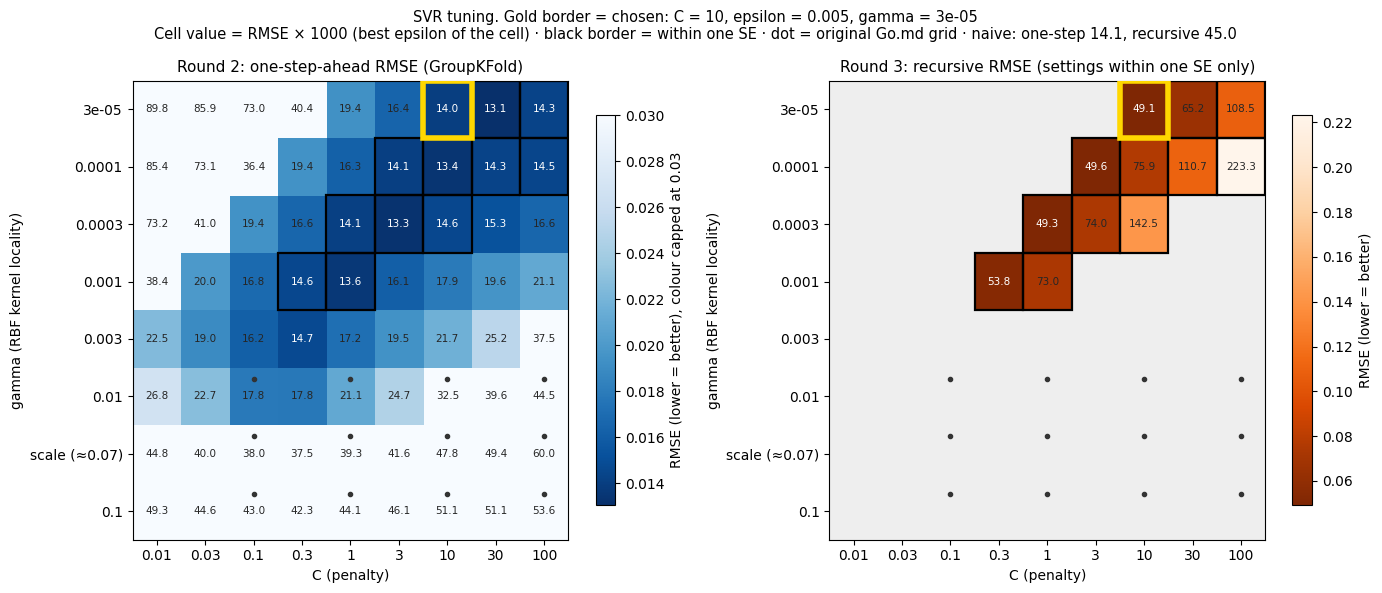

In [9]:
fig = exp.plotter.tuning_heatmap(exp.tuner)
plt.show()

## Step 5. Final model and forecasts (`SVRForecaster`, `RecursiveForecaster`)

Final model = the chosen setting, refitted on **all** training rows.

- **E1 (one step):** the lags are the **true** SOH of the previous cycles.
- **E2 (recursive):** stands at the first `is_eval` row (60% origin); each new forecast becomes `soh_lag1` of the next step. Measurements unknown after the origin (`chg_cc_time_s`, `Re_ohm`, `Rct_ohm`, `T_max_prev_C`, `log_rest_h`) are **held at their last known value**.

**95% interval for E1 (conformal):** out-of-fold residuals on the training batteries, q = 95th percentile of |error|, interval = ŷ ± q. No interval for E2, because the error grows with the horizon.

In [10]:
pred = exp.fit_predict()
cov = exp.forecaster.interval_coverage(pred)
print("half-width of the conformal interval q95 = %.4f SOH" % exp.forecaster.q_)
print("share of true values inside the E1 interval: %.1f%% (nominal level 95%%)" % (100 * cov))
pred.head()

half-width of the conformal interval q95 = 0.0300 SOH
share of true values inside the E1 interval: 91.1% (nominal level 95%)


,model,battery_id,cycle_valid,scenario,y_true,y_pred,y_lower,y_upper
0,svr,B0007,102,E1,0.829829,0.827145,0.797172,0.857117
1,svr,B0007,103,E1,0.832620,0.833597,0.803625,0.863569
2,svr,B0007,104,E1,0.837850,0.822614,0.792642,0.852586
3,svr,B0007,105,E1,0.832759,0.827066,0.797094,0.857038
4,svr,B0007,106,E1,0.827072,0.826292,0.796320,0.856265


**Reading the coverage.** If the share above is below 95%, the interval is too narrow on the test batteries. The reason: the out-of-fold residuals come from the training batteries, and the test batteries run under other conditions, so their errors are larger. The interval should therefore not be called "well calibrated".

## Step 6. Scoring against naive

The team's `evaluate()` checks that the prediction file has exactly the 213 `is_eval` rows in both scenarios, then computes MAE, RMSE, MAPE, R² and the E2 RUL error (`rul_error` > 0: late warning; < 0: early warning; `eol_pred` NaN: the forecast never reaches SOH 0.8).

In [11]:
metrics, rul = exp.evaluate()
exp.pooled_metrics().round(4)

n     MAE    RMSE  MAPE_pct      R2
scenario model                                       
E1       naive  213  0.0119  0.0226    1.4288  0.5001
         svr    213  0.0102  0.0172    1.2225  0.7091
E2       naive  213  0.0249  0.0343    3.1271 -0.1552
         svr    213  0.0476  0.0588    5.8139 -2.3864

In [12]:
pb = exp.per_battery_rmse()
print("E1: SVR beats naive on", int(pb.loc["E1"].svr_better.sum()), "of 4 test batteries")
print("E2: SVR beats naive on", int(pb.loc["E2"].svr_better.sum()), "of 4 test batteries")
pb.round(4)

E1: SVR beats naive on 3 of 4 test batteries
E2: SVR beats naive on 1 of 4 test batteries


model                 naive     svr  svr_better
scenario battery_id                            
E1       B0007       0.0037  0.0055       False
         B0034       0.0135  0.0125        True
         B0047       0.0172  0.0138        True
         B0055       0.0462  0.0331        True
E2       B0007       0.0515  0.0314        True
         B0034       0.0179  0.0847       False
         B0047       0.0199  0.0360       False
         B0055       0.0305  0.0433       False

In [13]:
soh_min = test.groupby("battery_id").soh.min()
print("lowest true SOH of each test battery (B0034 only just touches 0.8, so its RUL is fragile):")
print(soh_min.round(4).to_string())
rul

lowest true SOH of each test battery (B0034 only just touches 0.8, so its RUL is fragile):
battery_id
B0007    0.7464
B0034    0.7988
B0047    0.7444
B0055    0.7907


,model,battery_id,eol_true,eol_pred,rul_error
0,naive,B0007,126.0,NaN,NaN
1,naive,B0034,186.0,NaN,NaN
2,naive,B0055,65.0,NaN,NaN
3,svr,B0007,126.0,112.0,-14.0
4,svr,B0034,186.0,128.0,-58.0
5,svr,B0055,65.0,87.0,22.0


## Steps 7–8. Figure: true SOH and forecasts, E2 path to EOL

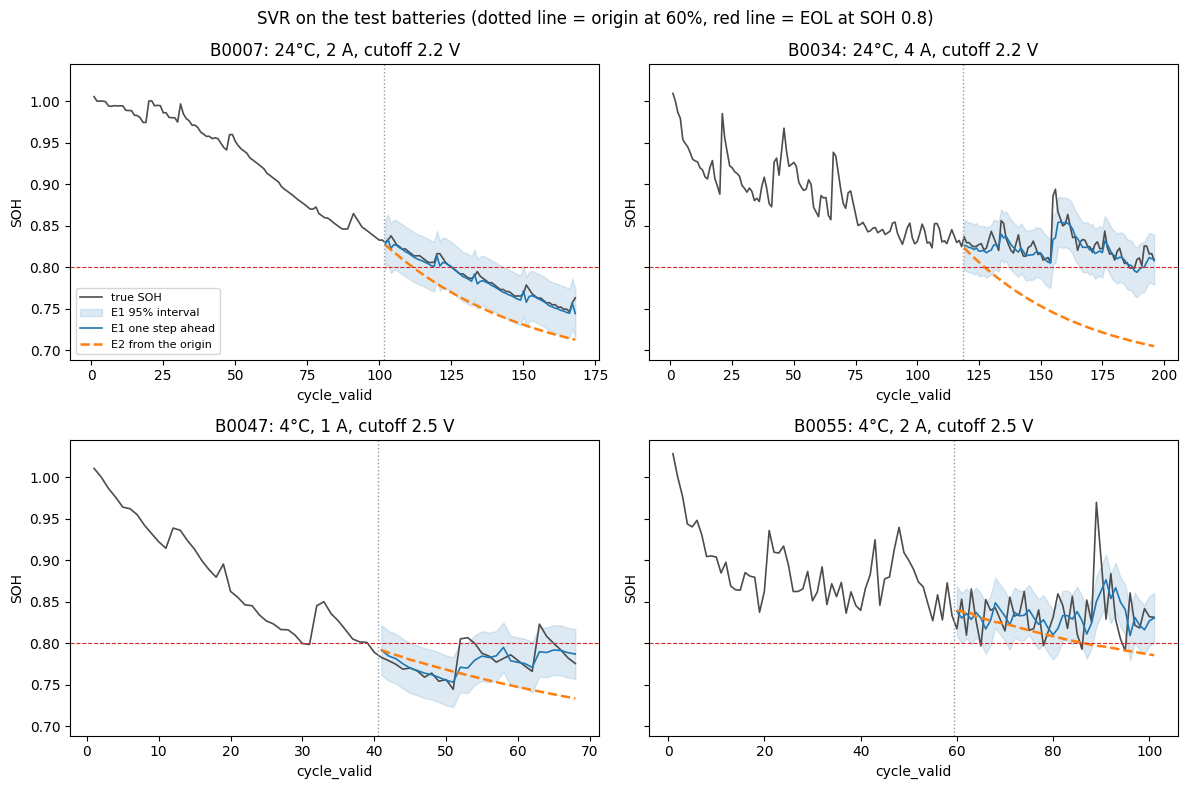

In [14]:
fig = exp.plotter.forecasts(test, pred)
plt.show()

## RQ4. Which features matter (`ImportanceAnalyzer`)

Each feature is shuffled on the E1 rows of the test set (30 times) and the increase in RMSE is measured. Because the 5 lags and `soh_roll5` carry almost the same information, shuffling one of them alone lets the model read it from the others, so we also shuffle the **whole SOH-history group** at once.

In [15]:
imp = exp.explain()
print("test RMSE (E1) before shuffling = %.5f" % exp.importance.base_rmse_)
imp.round(5)

test RMSE (E1) before shuffling = 0.01723


,feature,RMSE_increase,sd
0,[group] SOH history (lags 1-5 + roll5),0.02358,0.00123
1,soh_lag1,0.00540,0.00068
2,I_level_A,0.00341,0.00043
3,log_rest_h,0.00263,0.00024
4,soh_lag2,0.00171,0.00039
5,is_4C,0.00070,0.00024
6,soh_roll5,0.00057,0.00024
7,Re_ohm,0.00037,0.00019
8,chg_cc_time_s,0.00027,0.00012
9,T_max_prev_C,0.00017,0.00014


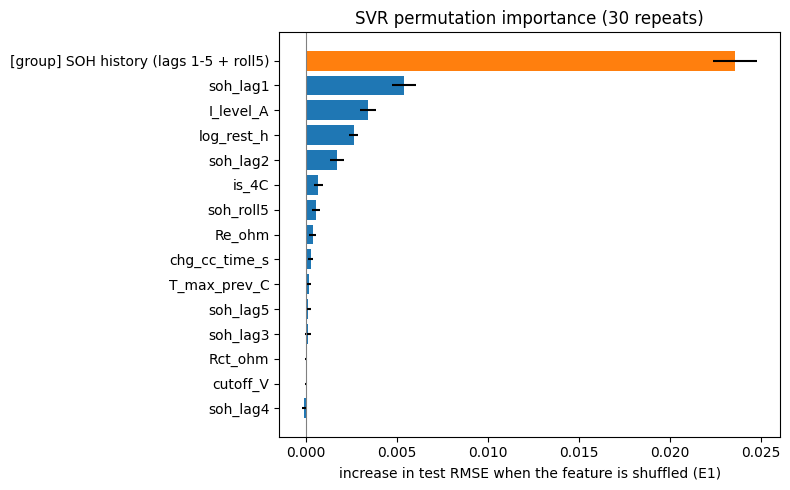

In [16]:
fig = exp.plotter.importance(imp)
plt.show()

In [17]:
v = imp.set_index("feature").RMSE_increase
charge_imp = ["chg_cc_time_s", "Re_ohm", "Rct_ohm"]
print("SOH-history group: %.5f" % v["[group] SOH history (lags 1-5 + roll5)"])
print("charge and impedance features:", {f: round(float(v[f]), 5) for f in charge_imp})
print("largest of them relative to the SOH-history group: %.1f%%"
      % (100 * v[charge_imp].max() / v["[group] SOH history (lags 1-5 + roll5)"]))

SOH-history group: 0.02358
charge and impedance features: {'chg_cc_time_s': 0.00027, 'Re_ohm': 0.00037, 'Rct_ohm': 1e-05}
largest of them relative to the SOH-history group: 1.6%


**Two cautions when reading the importance table**

1. `I_level_A` (and `is_4C`, `cutoff_V`) is constant within a battery. Shuffling it on the 4 test batteries in effect gives one battery the conditions of another. Its score therefore measures "operating conditions differ between batteries", not the effect of the discharge current within one battery.
2. The charge and impedance features (`chg_cc_time_s`, `Re_ohm`, `Rct_ohm`) add almost nothing once the recent SOH history is known (see the numbers printed above).

**Answer to RQ4.** For one-step forecasting, the recent SOH history carries almost all the information. Charge and impedance features forecast next-cycle SOH poorly on top of it. The rest time (`log_rest_h`) helps a little, because long rests are followed by a capacity-recovery jump that the SOH history cannot foresee.

**Link with the regression of Quoc Dat (WBS C6.4).** The regression shows that temperature, discharge current and cutoff voltage are related to the **rate** of degradation across batteries. The SVR shows that, once the recent SOH history is known, these variables add very little to a **one-step** forecast. The two results do not contradict each other: the conditions shape the slope of the whole curve, while the next cycle is mostly the previous cycle plus a small step. In numbers, the regression's conditional cycle slopes (`reports/tables/regression_conditional_cycle_slopes.csv`, at the training-average cutoff) are a relative SOH change of −0.35% per cycle at 4 °C/1 A, −0.17% at 4 °C/2 A and −0.33% at 24 °C/2 A, while the slope at 24 °C/4 A (+0.03%, p = 0.54) is not significant because only one training battery runs under that condition.

## Save the prediction file

In [18]:
path = exp.save()      # saves and re-checks with the team's evaluate()
print(f"{len(pred)} rows -> {path.relative_to(ROOT).as_posix()}")

426 rows -> reports/predictions/svr.csv


## Notes for the report (C6.6) and the review

- **E2 is the weak point.** The recursive SVR forecast loses to naive on the pooled metrics, and already lost to naive in cross-validation (step 4b). Likely reasons: errors accumulate step by step, and a model that learns from lags drifts towards the average degradation of the training batteries. This must be written plainly in the report.
- **E1 is good:** SVR beats naive on most test batteries (table in step 6). It can lose on a battery with a very smooth series, where naive is almost perfect.
- **RUL:** read the RUL table together with the lowest true SOH of each battery; B0034 only just touches 0.8.
- **The E1 interval is narrower than nominal** (coverage in step 5), and **E2 has no interval.** Both are limitations. A possible extension: simulate the recursive forecast many times, adding at each step noise drawn from the out-of-fold residuals, and take the 2.5% and 97.5% quantiles.
- **Decisions recorded in the Work_log (Minh Vu section):** grid extension (best parameters on the edge of the Go.md grid); one-SE rule with recursive RMSE as tie-break; edge check for γ along the C–γ ridge; E2 holds measurements at their last known value; conformal E1 interval; rows with missing Re/Rct dropped, not imputed.
- **Every number in the report must be read from the tables above, never typed by hand** (README section 9.7).